# Bayes' Theorem in AI: Filtering Spam with Naive Bayes

**Course:** AIT 525

**Assignment:** Final — Mathematics for AI

**By:** Yashu Lanki

## Purpose

This notebook backs up the numbers used in my final video presentation. It applies Bayes' theorem to the SMS Spam Collection (Almeida et al., 2011), first by hand for one word, then with a full Naive Bayes classifier built in scikit-learn (Pedregosa et al., 2011).

## Bayes' Theorem

Bayes' theorem updates a belief after seeing new evidence (Bayes, 1763):

$$P(\text{Spam} \mid \text{word}) = \frac{P(\text{word} \mid \text{Spam}) \, P(\text{Spam})}{P(\text{word})}$$

- **P(Spam)** is the *prior*: how common spam is before reading the message.
- **P(word | Spam)** is the *likelihood*: how often the word shows up in spam.
- **P(word)** is the *evidence*: how often the word shows up in any message.
- **P(Spam | word)** is the *posterior*: the updated chance the message is spam.

A Naive Bayes spam filter applies this to every word in a message at once, assuming the words are independent given the class (Sahami et al., 1998). It adds log-probabilities instead of multiplying small numbers, which keeps the math stable.

In [1]:
import csv
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

df = pd.read_csv("sms_data/SMSSpamCollection", sep="\t", header=None,
                 names=["label", "text"], quoting=csv.QUOTE_NONE)
df["spam"] = (df["label"] == "spam").astype(int)
print(df["label"].value_counts())
print("Total messages:", len(df))

label
ham     4827
spam     747
Name: count, dtype: int64
Total messages: 5574


## Step 1: Bayes' Theorem by Hand for the Word "free"

Each probability is just a count divided by a total.

In [2]:
has_free = df["text"].str.lower().str.contains(r"\bfree\b", regex=True)

p_spam = df["spam"].mean()                         # prior
p_free_given_spam = has_free[df["spam"] == 1].mean()  # likelihood
p_free_given_ham = has_free[df["spam"] == 0].mean()
p_free = has_free.mean()                            # evidence

posterior = p_free_given_spam * p_spam / p_free

print(f"P(Spam)          = {p_spam:.3f}")
print(f"P(free | Spam)   = {p_free_given_spam:.3f}")
print(f"P(free | Ham)    = {p_free_given_ham:.3f}")
print(f"P(free)          = {p_free:.3f}")
print(f"P(Spam | free)   = {posterior:.3f}")
print(f"Check by direct count: {df.loc[has_free, 'spam'].mean():.3f}")

P(Spam)          = 0.134
P(free | Spam)   = 0.228
P(free | Ham)    = 0.012
P(free)          = 0.041
P(Spam | free)   = 0.742
Check by direct count: 0.742


Seeing the word "free" raises the chance of spam from about 13% to about 74%. The direct count matches, which confirms the formula.

## Step 2: Naive Bayes Classifier

An 80/20 stratified train/test split, word counts as features, and a multinomial Naive Bayes model with Laplace (add-one) smoothing, so unseen words don't zero out the product.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    df["text"], df["spam"], test_size=0.2, stratify=df["spam"], random_state=42)

vectorizer = CountVectorizer()
X_train_counts = vectorizer.fit_transform(X_train)
X_test_counts = vectorizer.transform(X_test)

start = time.perf_counter()
model = MultinomialNB(alpha=1.0).fit(X_train_counts, y_train)
train_ms = (time.perf_counter() - start) * 1000

pred = model.predict(X_test_counts)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

print(f"Training time: {train_ms:.1f} ms on {X_train_counts.shape[0]} messages, {X_train_counts.shape[1]} words")
print(f"Accuracy:  {accuracy_score(y_test, pred):.3f}")
print(f"Precision: {precision_score(y_test, pred):.3f}")
print(f"Recall:    {recall_score(y_test, pred):.3f}")
print(f"Ham flagged as spam (false positives): {fp} of {tn + fp}")
print(f"Spam missed (false negatives): {fn} of {fn + tp}")

Training time: 1.0 ms on 4459 messages, 7716 words
Accuracy:  0.985
Precision: 0.978
Recall:    0.906
Ham flagged as spam (false positives): 3 of 966
Spam missed (false negatives): 14 of 149


## Step 3: Which Words Push a Message Toward Spam?

The likelihood ratio P(word | Spam) / P(word | Ham) shows how strongly each word points to spam. This is what makes Naive Bayes transparent: every decision can be traced back to the words.

lor             0.02
later           0.02
call            3.75
won             8.28
free            9.96
urgent         19.05
guaranteed    106.66
prize         191.99
claim         247.98
dtype: float64


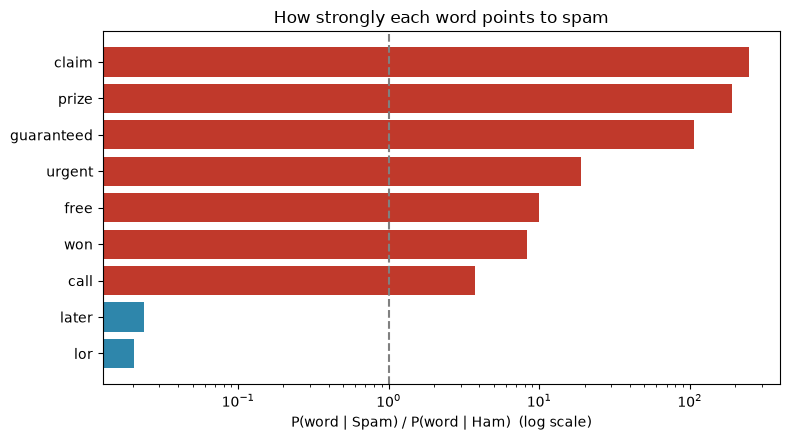

In [4]:
words = vectorizer.get_feature_names_out()
ratio = np.exp(model.feature_log_prob_[1] - model.feature_log_prob_[0])
lookup = dict(zip(words, ratio))

chosen = ["claim", "prize", "guaranteed", "urgent", "won", "free", "call", "later", "lor"]
ratios = pd.Series({w: lookup[w] for w in chosen}).sort_values()
print(ratios.round(2))

fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ["#C0392B" if r > 1 else "#2E86AB" for r in ratios]
ax.barh(ratios.index, ratios.values, color=colors)
ax.set_xscale("log")
ax.axvline(1, color="gray", linestyle="--")
ax.set_xlabel("P(word | Spam) / P(word | Ham)  (log scale)")
ax.set_title("How strongly each word points to spam")
plt.tight_layout()
plt.show()

## Key Findings

- About 13.4% of messages are spam, which is the prior.
- One word ("free") moves the spam probability from about 13% to about 74%.
- The Naive Bayes model trains in milliseconds and scores about 98.5% accuracy, with only 3 legitimate messages wrongly flagged out of 966 and about 91% of spam caught.
- Words like "claim" and "prize" are over 100 times more likely in spam, while casual words like "later" and "lor" point to legitimate messages.

## References

Almeida, T. A., Gómez Hidalgo, J. M., & Yamakami, A. (2011). Contributions to the study of SMS spam filtering: New collection and results. In *Proceedings of the 11th ACM Symposium on Document Engineering* (pp. 259–262). ACM. https://doi.org/10.1145/2034691.2034742

Almeida, T. A., & Gómez Hidalgo, J. M. (2011). *SMS spam collection* [Data set]. UCI Machine Learning Repository. Retrieved October 23, 2026, from https://doi.org/10.24432/C5CC84

Bayes, T. (1763). An essay towards solving a problem in the doctrine of chances. *Philosophical Transactions of the Royal Society of London, 53*, 370–418. https://doi.org/10.1098/rstl.1763.0053

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Sahami, M., Dumais, S., Heckerman, D., & Horvitz, E. (1998). A Bayesian approach to filtering junk e-mail. In *Learning for Text Categorization: Papers from the 1998 Workshop* (AAAI Technical Report WS-98-05). AAAI Press.